[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QGAN_FederatedIntrusionDetection_Cirillo2025.ipynb)

# Federated quantum GAN for intrusion detection: Cirillo and Esposito 2025 step by step

**Paper.** Franco Cirillo and Christian Esposito, *Federated Quantum Generative Adversarial Network for Intrusion Detection*, 2025 IEEE 45th International Conference on Distributed Computing Systems Workshops (ICDCSW), pp. 69-74. DOI: [10.1109/ICDCSW63273.2025.00018](https://doi.org/10.1109/ICDCSW63273.2025.00018). The authors' code is cited as `github.com/francocirill/fqgan` (not used here: this notebook is written from the paper text only).

**What this notebook does.** It rebuilds the paper's idea from scratch: a *quantum generator* (a 4-qubit variational circuit: Hadamards, `ZZFeatureMap` that loads a random noise vector, `EfficientSU2` ansatz) is trained against a *classical neural discriminator* on the **benign** NSL-KDD flows only. Four simulated clients each hold a shard of the benign data, train locally for one epoch and then average generator and discriminator weights (federated averaging, FedAvg). The trained discriminator is then used as an anomaly detector: a flow that does not look "real benign" gets a low score and is flagged as an attack. The notebook also trains the same QGAN on one machine (to check the paper's claim that federation does not hurt), a classical GAN with the same discriminator (does the quantum generator matter?), and classical detectors on exactly the same four input features.

**How to run it.** Open it in Google Colab (CPU runtime is enough, no GPU and no quantum hardware), choose *Runtime -> Run all*. With `FAST_MODE = True` (default) it finishes in about 10 minutes; `FAST_MODE = False` uses the larger budgets listed in the configuration cell. The quantum circuit is simulated exactly (4 qubits).

**What you get at the end.** Real-data exploration plots, the drawn generator circuits, the federated training curves (generator loss, discriminator loss on real and fake data), real versus generated samples, a confusion matrix, the accuracy / F1 of every model next to the paper's 0.9125 / 0.9034, an ablation of the ansatz, depth and learning rate, and a claim-by-claim verdict table.

## The paper in one page

**Problem.** Network intrusion detection by anomaly detection: learn what *benign* traffic looks like and flag everything else. GANs can model the benign distribution; quantum GANs (QGANs) might do so with fewer parameters; federated learning spreads the (slow) quantum simulation over several nodes and keeps raw data local.

**Decision.** Normal versus attack (attack is the positive class in this notebook; the paper does not say which class is positive).

**Data.** NSL-KDD (the paper does not say which file or which sample size). Numeric and categorical features, scaled to [0, 1] with Min-Max, then PCA to **4 components** (one per qubit).

**Model (Section IV).**
* Generator = variational quantum circuit on 4 qubits: Hadamard on every qubit, a feature map (`ZZFeatureMap`) that encodes the random latent / noise vector, then the trainable `EfficientSU2` ansatz (3 repetitions in the best configuration). The 16 measurement probabilities are mapped to 4 numbers by the **interpret function**: the marginal probability that each qubit is 1. These 4 numbers in [0, 1] are a synthetic PCA-feature vector.
* Discriminator = classical feed-forward network with dense hidden layers, LeakyReLU, sigmoid output, binary cross-entropy loss.
* Training = standard GAN losses (Eq. 1 and 2), Adam, 80 epochs, learning rates 0.001 and 0.0006.
* Federated version = 4 independent QGANs, each on its own data subset and with its own generator seed; **after every epoch the generator weights and the discriminator weights of all clients are averaged** and every client starts the next epoch from the average.

**Claims.**
1. Final accuracy **0.9125** and F1-score **0.9034** (Section V; the conclusion repeats them).
2. The federated QGAN reaches performance comparable to a single QGAN trained on all the data, in **about a quarter of the time** (24 h for the single model versus 6 h for four clients).
3. EfficientSU2 is marginally better than RealAmplitudes; 3 ansatz repetitions balance accuracy and time; learning rate 0.01 is unstable, 0.001 is stable but lets the discriminator win, 0.001 / 0.0006 balances the two; the generator loss falls while the discriminator loss on fake data rises (Figure 3).

### What follows the paper and what had to be chosen

The paper is a 6-page workshop paper. It gives the architecture, the optimiser and the headline metrics, but not the data split, the threshold that turns the discriminator score into a decision, the discriminator size, the batch size or the noise distribution. Every such choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD (file and size not stated) | `KDDTrain+` and `KDDTest+` from the public GitHub mirror `defcom17/NSL_KDD`; a stratified 80 / 20 split of `KDDTrain+` is the main test set, `KDDTest+` is a second, harder test set |
| Preprocessing | Min-Max to [0, 1], PCA with 4 components | one-hot categoricals, `log1p` on heavy-tailed counts (CHOICE), Min-Max, PCA(4), then a robust rescale of the 4 components to [0, 1] and clipping; all fitted on the training split only (no labels used) |
| What the GAN is trained on | benign data ("learns the distribution of benign data") | benign training flows only; attacks are never shown to the GAN |
| Generator circuit | H on all qubits, `ZZFeatureMap` for the noise, `EfficientSU2` (3 reps), Adam | the same (Qiskit 2.x circuit library); `ZZFeatureMap` uses Qiskit's default 2 repetitions and full entanglement; noise `z ~ U[0, pi]^4` (CHOICE) |
| Interpret function | marginal probability of each qubit being 1 | the same, computed exactly from the state vector |
| Discriminator | dense layers, LeakyReLU, sigmoid, BCE | 4-32-16-1 dense network with LeakyReLU(0.2) (CHOICE) |
| Learning rates | "0.001 and 0.0006" (which network gets which is not stated) | generator 0.001, discriminator 0.0006 (CHOICE: the paper says the discriminator was too fast at 0.001, so it gets the smaller rate) |
| Epochs | 80 | 80 in the full run, fewer in `FAST_MODE` |
| Federation | 4 QGANs, different generator seeds, average G and D after every epoch | the same, simulated sequentially on one CPU; shards are random, equal-sized and IID (CHOICE) |
| Score to decision | not stated ("probability score") | attack if `D(x)` is below a threshold: (a) the 5 % quantile of `D` on held-out benign flows (no attack label needed), (b) the threshold that maximises F1 on a labelled validation split of the training data. Both are reported (CHOICE) |
| Test set / size | not stated; 0.9125 = 73/80, so possibly a very small test set | the full 20 % hold-out of `KDDTrain+` (about 25,000 flows) and `KDDTest+` |
| Hardware / simulator | not stated (6 h federated, 24 h single) | exact state-vector simulation in PyTorch, asserted equal to Qiskit's `Statevector` of the drawn circuit |
| Timings | 24 h vs 6 h | the clients run one after the other here; the parallel time is the sum over epochs of the slowest client (an estimate, labelled as such) |

## 1. Setup

The first cell installs pinned, tested versions (it does nothing locally if they are already importable). On Colab a *session restart* may be requested after the install; if so, run all cells again. PyTorch and scikit-learn come with Colab.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_aer", "sympy", "torch"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc", "sympy"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo (small benign pool, fewer epochs, one seed, two ablation circuits); `FAST_MODE = False` follows the paper's 80 epochs and adds seeds and the ablations on depth and learning rate. The paper's own scale (24 h / 6 h of simulation, data size unknown) is not reproduced; the budgets below are what a CPU notebook can do.

In [2]:
FAST_MODE = True            # True: demo (about 6-10 min). False: 80 epochs, 3 seeds, full ablation grid (45 min to 2 h on a laptop CPU, depending on load)
SEED = 42                   # global seed: data split, torch, numpy
DATA_DIR = "data"           # downloads are cached here
IBM_TOKEN = ""              # unused: the paper has no real-hardware numbers
SHOTS = 4096                # only used for the sampler cross-check of the trained generator (training is exact)

N_QUBITS = 4                # paper: PCA with 4 components, one qubit per feature
N_CLIENTS = 4               # paper: a network of four QGANs
FM_REPS = 2                 # CHOICE: ZZFeatureMap repetitions (Qiskit default; the paper does not say)
ANSATZ, ANSATZ_REPS = "EfficientSU2", 3     # paper: EfficientSU2, 3 repetitions
LR_G, LR_D = 1e-3, 6e-4     # CHOICE: paper "0.001 and 0.0006"; the discriminator was too fast at 0.001, so it gets the smaller rate
BATCH = 64                  # CHOICE: not stated
BENIGN_FPR = 0.05           # CHOICE: unsupervised threshold = 5 % quantile of D on held-out benign flows
N_VAL_LAB = 6000            # CHOICE: labelled validation flows (training split) used for threshold rule (b) and AUC curves
N_BENIGN_VAL = 2000         # CHOICE: held-out benign flows for threshold rule (a)
PAPER = dict(acc=0.9125, f1=0.9034, t_single_h=24.0, t_fed_h=6.0)
TOL = 0.02                  # a claim is "reproduced" when within 0.02 accuracy / F1 (2 points)

if FAST_MODE:
    EPOCHS, N_BENIGN_POOL = 20, 3200                       # paper: 80 epochs; data size unknown
    SEEDS = [42]
    ARCHS = [("EfficientSU2", 3), ("RealAmplitudes", 3)]   # circuits that are trained and compared
    LR_ABLATION = False
else:
    EPOCHS, N_BENIGN_POOL = 80, 6400                       # 1600 benign flows per client (paper: data size unknown, 6 h on 4 nodes)
    SEEDS = [42, 43, 44]
    ARCHS = [("EfficientSU2", 3), ("RealAmplitudes", 3), ("EfficientSU2", 2), ("EfficientSU2", 1)]
    LR_ABLATION = True                                     # paper: lr 0.01 unstable, 0.001 stable
print("FAST_MODE =", FAST_MODE, "| epochs", EPOCHS, "| benign pool", N_BENIGN_POOL, "| seeds", SEEDS, "| architectures", ARCHS)

FAST_MODE = True | epochs 20 | benign pool 3200 | seeds [42] | architectures [('EfficientSU2', 3), ('RealAmplitudes', 3)]


In [3]:
import os, time, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, torch, torch.nn as nn
import sympy
warnings.filterwarnings("ignore")
import qiskit, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterExpression
from qiskit.circuit.library import zz_feature_map, efficient_su2, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC, OneClassSVM
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from scipy.stats import ks_2samp
from IPython.display import display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)                                    # tiny tensors: one thread is fastest (and kind to a shared CPU)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| torch", torch.__version__, "| sympy", sympy.__version__)

qiskit 2.5.2 | qiskit-aer 0.17.2 | torch 2.14.1+cpu | sympy 1.14.0


## 2. Data: NSL-KDD

NSL-KDD is the cleaned version of KDD Cup 99: 41 features per network connection (3 categorical: protocol, service, flag; the rest numeric) and a label with 22 attack names in `KDDTrain+` (more in `KDDTest+`) that group into four families: **DoS**, **Probe**, **R2L**, **U2R**. The notebook downloads both files from a public GitHub mirror (with a second mirror as fallback). The Hugging Face token mechanism of this project is not needed because the data are public.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# NSL-KDD is public on GitHub: no token is needed or used. (A gated dataset would need the reader's own token in Colab Secrets.)

NSL_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack", "difficulty"]
FAMILY = {"normal": "Normal"}
for fam_, names in {"DoS": "back land neptune pod smurf teardrop apache2 udpstorm processtable worm mailbomb",
                    "Probe": "ipsweep nmap portsweep satan mscan saint",
                    "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop httptunnel",
                    "U2R": "buffer_overflow loadmodule perl rootkit ps sqlattack xterm"}.items():
    FAMILY.update({n: fam_ for n in names.split()})
URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                          "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
        "KDDTest+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                         "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"]}

def download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            print("download failed:", u, repr(e)[:100])
    raise RuntimeError("no mirror worked for " + path)

def load_nsl(name):
    path = download(URLS[name], os.path.join(DATA_DIR, name))
    raw = pd.read_csv(path, header=None, names=NSL_COLS)
    raw["family"] = raw["attack"].map(FAMILY).fillna("Other")
    raw["y"] = (raw["attack"] != "normal").astype(int)         # 0 = normal, 1 = attack (positive class)
    return raw

RAW_TR, RAW_TE = load_nsl("KDDTrain+.txt"), load_nsl("KDDTest+.txt")
print("KDDTrain+:", RAW_TR.shape, "| attack share", round(RAW_TR.y.mean(), 3), "| KDDTest+:", RAW_TE.shape, "| attack share", round(RAW_TE.y.mean(), 3))
print("unmapped attack names:", sorted(set(RAW_TR.attack[RAW_TR.family == "Other"]) | set(RAW_TE.attack[RAW_TE.family == "Other"])))

KDDTrain+: (125973, 45) | attack share 0.465 | KDDTest+: (22544, 45) | attack share 0.569
unmapped attack names: []


### 2.1 Splits

All labels are used **only** for (i) the stratified split, (ii) choosing a decision threshold on a validation set and (iii) scoring. The GAN sees nothing but benign flows. The splits of `KDDTrain+` (stratified by attack family):

* **hold-out test set** (20 %): the main test set, natural benign / attack mix;
* **training split** (80 %), which is divided into a small **labelled validation set** (thresholds, learning curves), a **benign validation set** (unsupervised threshold), and the **benign pool** that the GAN trains on, cut into one shard per client.

`KDDTest+` (the official test file, with attacks absent from training) is kept as a second, harder test set.

In [5]:
FEATURES = [c for c in NSL_COLS if c not in ("attack", "difficulty")]
CAT = ["protocol_type", "service", "flag"]
fam_all, y_all = RAW_TR["family"].values, RAW_TR["y"].values

idx = np.arange(len(RAW_TR))
TR_ALL, HO = train_test_split(idx, test_size=0.2, stratify=fam_all, random_state=SEED)            # training split / hold-out test
VAL_LAB, REST = train_test_split(TR_ALL, train_size=N_VAL_LAB, stratify=fam_all[TR_ALL], random_state=SEED)
rest_benign = np.random.default_rng(SEED).permutation(REST[y_all[REST] == 0])
BEN_VAL = rest_benign[:N_BENIGN_VAL]                                                               # benign validation (threshold rule a)
POOL = rest_benign[N_BENIGN_VAL:N_BENIGN_VAL + N_BENIGN_POOL]                                      # benign pool for the GAN
print(f"training split {len(TR_ALL):,} | labelled validation {len(VAL_LAB):,} | benign validation {len(BEN_VAL):,} | benign GAN pool {len(POOL):,} (of {len(rest_benign) - N_BENIGN_VAL:,} available)")
print(f"hold-out test {len(HO):,} (attack share {y_all[HO].mean():.3f}) | KDDTest+ {len(RAW_TE):,} (attack share {RAW_TE.y.mean():.3f})")
assert not (set(POOL) & set(HO)) and not (set(POOL) & set(VAL_LAB)) and not (set(POOL) & set(BEN_VAL)), "leakage between splits"

training split 100,778 | labelled validation 6,000 | benign validation 2,000 | benign GAN pool 3,200 (of 48,666 available)
hold-out test 25,195 (attack share 0.465) | KDDTest+ 22,544 (attack share 0.569)


### 2.2 Preprocessing (fitted on the training split only, no labels)

Following Section IV-A: one-hot encode the categorical columns, Min-Max scale to [0, 1], PCA with 4 components. Choices where the paper is silent: a `log1p` on columns with a heavy tail (byte counts and similar, otherwise they squash everything else after Min-Max), and a final robust rescale of each principal component to [0, 1] (0.5 % and 99.5 % quantiles of the training split) with clipping, so that the real data live in the same [0, 1] range as the generator's marginal probabilities. Every transform is fitted on the 80 % training split (features only); the hold-out and `KDDTest+` flows are only transformed.

In [6]:
class Prep:
    """one-hot -> log1p on heavy-tailed columns -> MinMax[0,1] -> PCA(N_QUBITS) -> robust rescale to [0,1]. Fitted on feature rows only (no labels)."""
    def fit(self, df):
        self.ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(df[CAT])
        num = df.drop(columns=CAT)
        self.num_cols = [c for c in num.columns if num[c].nunique() > 1]
        self.log_cols = [c for c in self.num_cols if num[c].max() > 10]                      # CHOICE: heavy-tailed columns get log1p
        self.mm = MinMaxScaler().fit(self._raw(df))
        B = self.mm.transform(self._raw(df))
        self.pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(B)
        P = self.pca.transform(B)
        self.lo, self.hi = np.percentile(P, [0.5, 99.5], axis=0)                              # CHOICE: robust range of each component
        return self
    def _raw(self, df):
        num = df[self.num_cols].copy().astype(float)
        for c in self.log_cols:
            num[c] = np.log1p(num[c].clip(lower=0))
        return np.hstack([num.values, self.ohe.transform(df[CAT])])
    def full(self, df):                      # all preprocessed features before PCA (for the all-feature baseline)
        return self.mm.transform(self._raw(df))
    def pca_coords(self, df):                # raw PCA coordinates
        return self.pca.transform(self.full(df))
    def unit(self, df):                      # PCA coordinates rescaled to [0, 1] and clipped (the GAN's data space)
        return np.clip((self.pca_coords(df) - self.lo) / (self.hi - self.lo), 0, 1)

prep = Prep().fit(RAW_TR.loc[TR_ALL, FEATURES])
print("numeric columns kept:", len(prep.num_cols), "| log1p on", len(prep.log_cols), "| one-hot columns:", prep.ohe.transform(RAW_TR.loc[TR_ALL[:2], CAT]).shape[1],
      "| PCA explained variance ratio:", np.round(prep.pca.explained_variance_ratio_, 3), "(sum %.3f)" % prep.pca.explained_variance_ratio_.sum())
U = {name: prep.unit(df[FEATURES]) for name, df in [("train", RAW_TR.loc[TR_ALL]), ("pool", RAW_TR.loc[POOL]), ("benval", RAW_TR.loc[BEN_VAL]),
                                                   ("val", RAW_TR.loc[VAL_LAB]), ("ho", RAW_TR.loc[HO]), ("kddtest", RAW_TE)]}
Y = {"train": y_all[TR_ALL], "pool": y_all[POOL], "benval": y_all[BEN_VAL], "val": y_all[VAL_LAB], "ho": y_all[HO], "kddtest": RAW_TE["y"].values}
FAMS = {"train": fam_all[TR_ALL], "ho": fam_all[HO], "val": fam_all[VAL_LAB], "kddtest": RAW_TE["family"].values}
print({k: v.shape for k, v in U.items()}, "| fraction of hold-out coordinates clipped:", round(float(((prep.pca_coords(RAW_TR.loc[HO, FEATURES]) - prep.lo) / (prep.hi - prep.lo) < 0).mean() + ((prep.pca_coords(RAW_TR.loc[HO, FEATURES]) - prep.lo) / (prep.hi - prep.lo) > 1).mean()), 4))

numeric columns kept: 37 | log1p on 11 | one-hot columns: 84 | PCA explained variance ratio: [0.409 0.159 0.11  0.049] (sum 0.727)


{'train': (100778, 4), 'pool': (3200, 4), 'benval': (2000, 4), 'val': (6000, 4), 'ho': (25195, 4), 'kddtest': (22544, 4)} | fraction of hold-out coordinates clipped: 0.0108


## Dataset Exploration and Visualisation

NSL-KDD is a table of real connection records that the notebook downloads; nothing in this section is simulated. It prints shape, feature names and original labels with class counts, plots the real class distribution (original attack names, attack family and the binary label), and draws 2-D scatter plots of **real training flows coloured by their ground-truth family**: first the raw PCA coordinates (PC1 against PC2, fitted on the training split), then the same flows in the [0, 1] range that is the data space of the GAN (the quantum generator has no angle-encoded data input: its noise is angle-encoded, its *output* is compared with these [0, 1] coordinates). Labels are only used for colouring.

In [7]:
print("KDDTrain+ shape:", RAW_TR.shape, "| KDDTest+ shape:", RAW_TE.shape)
print("\n41 original features:", FEATURES)
print("\noriginal label column 'attack' in KDDTrain+ (", RAW_TR.attack.nunique(), "distinct values):")
print(RAW_TR.attack.value_counts().to_string())
print("\nattack family counts, KDDTrain+:", dict(RAW_TR.family.value_counts()))
print("attack family counts, KDDTest+ :", dict(RAW_TE.family.value_counts()))
print("binary label (0 = normal, 1 = attack), KDDTrain+:", dict(RAW_TR.y.value_counts()), "| GAN benign pool:", len(POOL), "flows, all label 0")
print("attack names in KDDTest+ that never occur in KDDTrain+:", sorted(set(RAW_TE.attack) - set(RAW_TR.attack)))

KDDTrain+ shape: (125973, 45) | KDDTest+ shape: (22544, 45)

41 original features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

original label column 'attack' in KDDTrain+ ( 23 distinct values):
attack
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep    

attack names in KDDTest+ that never occur in KDDTrain+: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


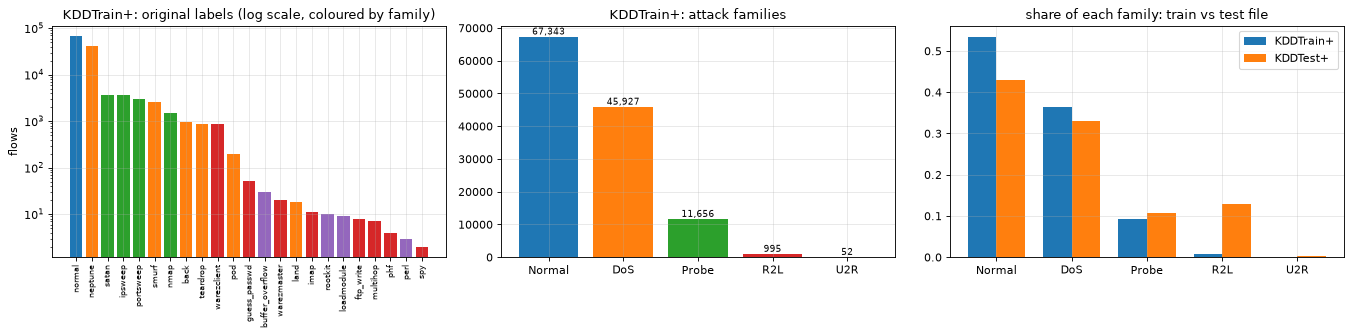

In [8]:
fam_order = list(RAW_TR.family.value_counts().index)
cmap10 = plt.get_cmap("tab10"); fam_col = {f: cmap10(i) for i, f in enumerate(fam_order)}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
vc = RAW_TR.attack.value_counts()
ax[0].bar(range(len(vc)), vc.values, color=[fam_col[FAMILY.get(a, "Other")] for a in vc.index]); ax[0].set_xticks(range(len(vc))); ax[0].set_xticklabels(vc.index, rotation=90, fontsize=7)
ax[0].set_yscale("log"); ax[0].set_title("KDDTrain+: original labels (log scale, coloured by family)"); ax[0].set_ylabel("flows")
fc = RAW_TR.family.value_counts(); ax[1].bar(fc.index, fc.values, color=[fam_col[f] for f in fc.index]); ax[1].set_title("KDDTrain+: attack families")
for k, v in enumerate(fc.values): ax[1].text(k, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
w = 0.38; fte = RAW_TE.family.value_counts().reindex(fam_order).fillna(0)
ax[2].bar(np.arange(len(fam_order)) - w / 2, fc.reindex(fam_order).values / len(RAW_TR), w, label="KDDTrain+"); ax[2].bar(np.arange(len(fam_order)) + w / 2, fte.values / len(RAW_TE), w, label="KDDTest+")
ax[2].set_xticks(range(len(fam_order))); ax[2].set_xticklabels(fam_order); ax[2].set_title("share of each family: train vs test file"); ax[2].legend()
plt.tight_layout(); plt.show()

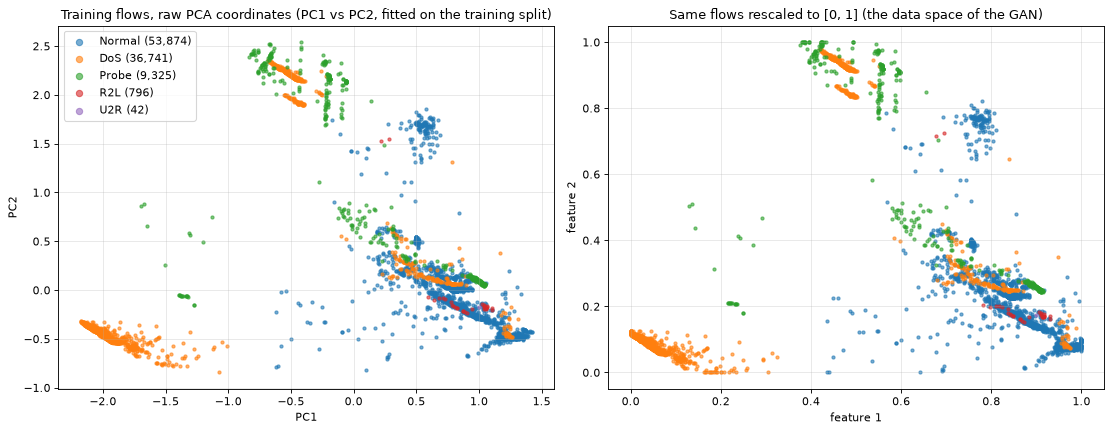

5000 random real training flows shown, coloured by ground-truth family.


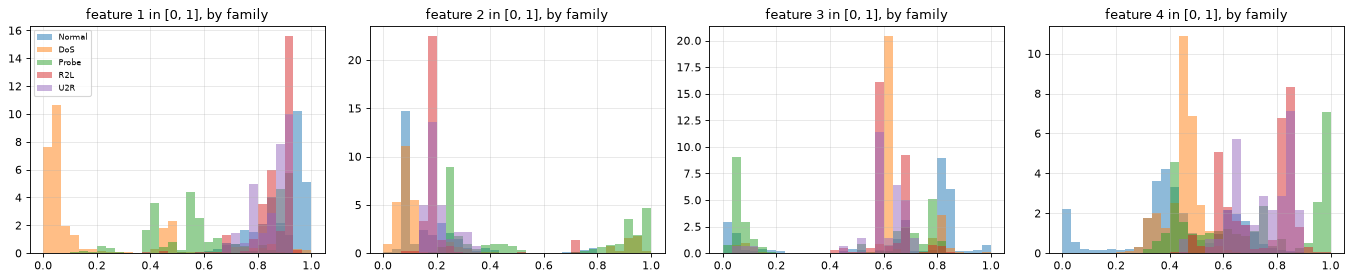

In [9]:
sel = np.random.default_rng(SEED).choice(len(TR_ALL), size=5000, replace=False)
P2 = prep.pca_coords(RAW_TR.loc[TR_ALL[sel], FEATURES]); U2 = U["train"][sel]; f2 = FAMS["train"][sel]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for f in fam_order:
    m = f2 == f
    ax[0].scatter(P2[m, 0], P2[m, 1], s=8, alpha=0.6, color=fam_col[f], label=f"{f} ({(FAMS['train'] == f).sum():,})")
    ax[1].scatter(U2[m, 0], U2[m, 1], s=8, alpha=0.6, color=fam_col[f])
ax[0].set_title("Training flows, raw PCA coordinates (PC1 vs PC2, fitted on the training split)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(markerscale=2)
ax[1].set_title("Same flows rescaled to [0, 1] (the data space of the GAN)"); ax[1].set_xlabel("feature 1"); ax[1].set_ylabel("feature 2")
plt.tight_layout(); plt.show()
print("5000 random real training flows shown, coloured by ground-truth family.")
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for k in range(N_QUBITS):
    for f in fam_order:
        ax[k].hist(U["train"][FAMS["train"] == f][:, k], bins=30, range=(0, 1), alpha=0.5, color=fam_col[f], density=True, label=f)
    ax[k].set_title(f"feature {k + 1} in [0, 1], by family")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**What the plots show.** The two big families, Normal and DoS, are partly separated in the first two components, Probe sits in between and R2L / U2R (tiny families) overlap with Normal. Only benign flows (the green cloud) are shown to the GAN; the attacks are what the discriminator has to recognise as "not like the benign cloud". Because the first four components keep only part of the variance, some attacks are hard to separate from benign flows in this 4-D space, which caps what any detector on these inputs can reach.

## Quantum Circuit Architecture

The generator of Section IV-B, built with Qiskit's function-style circuit library: Hadamard on every qubit, `zz_feature_map` that loads the 4-dimensional noise vector `x`, the trainable `efficient_su2` (or `real_amplitudes`) ansatz with parameters `theta`, and a measurement of all qubits. The state is simulated *exactly* for training with a small differentiable PyTorch state-vector simulator that executes **the gate list of this very Qiskit circuit** (after Qiskit writes its composite blocks as `h`, `p`, `cx`, `ry`, `rz`); a cell asserts that its output probabilities equal Qiskit's `Statevector` result for random noise and weights. (For speed the simulator multiplies consecutive single-qubit rotations of one qubit into one 2x2 matrix, which is exact, and builds the unitary of the trainable block once per training step; the noise-dependent first part of the circuit is evaluated once per epoch because it does not depend on the weights.) Assumptions where the paper is silent: `ZZFeatureMap` with Qiskit's default 2 repetitions and full entanglement; `EfficientSU2` / `RealAmplitudes` with Qiskit's default entanglement; initial weights drawn uniformly from [-pi, pi]; noise `z ~ U[0, pi]^4`.

--- generator EfficientSU2, reps=3: 4 qubits | 4 noise inputs | 32 trainable parameters | depth (high level) 48 | depth (elementary gates) 47


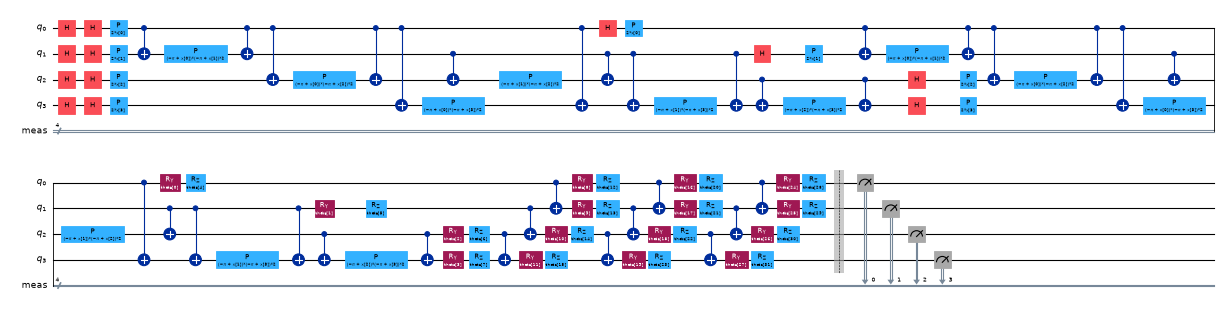

--- generator RealAmplitudes, reps=3: 4 qubits | 4 noise inputs | 16 trainable parameters | depth (high level) 44 | depth (elementary gates) 43


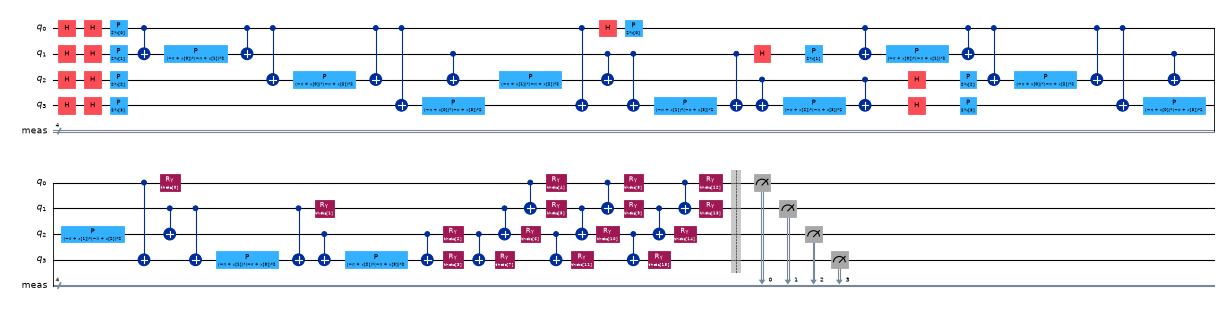

,circuit,qubits,depth_elementary,trainable_params,noise_inputs,cx
0,EfficientSU2 reps=3,4,47,32,4,33
1,RealAmplitudes reps=3,4,43,16,4,33


In [10]:
BASIS = ["h", "p", "cx", "ry", "rz"]

def build_parts(ansatz="EfficientSU2", reps=3, fm_reps=FM_REPS, n=N_QUBITS):
    """The two blocks of the generator: noise block (Hadamards + ZZFeatureMap) and trainable block (ansatz)."""
    fm = zz_feature_map(n, reps=fm_reps, parameter_prefix="x")
    an = {"EfficientSU2": efficient_su2, "RealAmplitudes": real_amplitudes}[ansatz](n, reps=reps, parameter_prefix="theta")
    noise = QuantumCircuit(n); noise.h(range(n)); noise.compose(fm, inplace=True)
    return noise, an, list(fm.parameters), list(an.parameters)

def build_generator(ansatz="EfficientSU2", reps=3, fm_reps=FM_REPS, n=N_QUBITS, measure=False):
    """Hadamards + ZZFeatureMap(noise) + trainable ansatz (+ measurement of every qubit)."""
    noise, an, xp, tp = build_parts(ansatz, reps, fm_reps, n)
    qc = noise.compose(an)
    if measure:
        qc.measure_all()
    return qc, xp, tp

def circuit_stats(qc, title):
    dec = transpile(qc.remove_final_measurements(inplace=False), basis_gates=BASIS, optimization_level=0)
    return dict(circuit=title, qubits=qc.num_qubits, depth_elementary=dec.depth(), trainable_params=sum(1 for p in qc.parameters if p.name.startswith("theta")),
                noise_inputs=sum(1 for p in qc.parameters if p.name.startswith("x")), cx=dec.count_ops().get("cx", 0), ops=dict(dec.count_ops()))

ARCH_ROWS = []
for ans, reps in ARCHS:
    qcm, xp, tp = build_generator(ans, reps, measure=True)
    ARCH_ROWS.append(circuit_stats(qcm, f"{ans} reps={reps}"))
    print(f"--- generator {ans}, reps={reps}: {qcm.num_qubits} qubits | {len(xp)} noise inputs | {len(tp)} trainable parameters | depth (high level) {qcm.depth()} | depth (elementary gates) {ARCH_ROWS[-1]['depth_elementary']}")
    display(qcm.draw("mpl", fold=45, scale=0.5))
    plt.close("all")
display(pd.DataFrame(ARCH_ROWS).drop(columns="ops"))

**Reading the drawings.** Left block: four Hadamards and then the `ZZFeatureMap` (box labelled with the noise parameters `x[0] ... x[3]`; each repetition is Hadamards, a phase `P(2 x_i)` on every qubit and, for every pair of qubits, CX - `P(2 (pi - x_i)(pi - x_j))` - CX, which is where the noise values become entangled). Middle: the trainable ansatz (`ry`, `rz` rotation layers and CX entanglers; `RealAmplitudes` has only `ry`). Right: measurement of the four qubits. The interpret function is applied to the 16 outcome probabilities: it is classical post-processing, so it is not part of the circuit.

The next cells compile the circuit into a gate list for the PyTorch simulator and check it against Qiskit.

In [11]:
class TorchGenerator(nn.Module):
    """Differentiable exact simulator of the generator circuit. The gate list comes from the Qiskit circuit itself
    (transpiled to h/p/cx/ry/rz); angle expressions are evaluated with sympy -> torch."""
    def __init__(self, ansatz="EfficientSU2", reps=3, fm_reps=FM_REPS, n=N_QUBITS, init_seed=0):
        super().__init__()
        self.n = n; self.ansatz, self.reps = ansatz, reps
        self.qc, self.xp, self.tp = build_generator(ansatz, reps, fm_reps, n)
        noise_c, train_c, _, _ = build_parts(ansatz, reps, fm_reps, n)
        self.xnames = {p.name: k for k, p in enumerate(self.xp)}; self.tnames = {p.name: k for k, p in enumerate(self.tp)}
        def compile_ops(circ):
            dec = transpile(circ, basis_gates=BASIS, optimization_level=0); ops = []
            for inst in dec.data:
                op = inst.operation; qs = tuple(dec.find_bit(q).index for q in inst.qubits)
                ang = None
                if op.params:
                    e = op.params[0]
                    if isinstance(e, ParameterExpression):
                        sym = e.sympify(); syms = sorted(sym.free_symbols, key=str)
                        ang = (sympy.lambdify(syms, sym, modules=[{"pi": math.pi}, "math"], dummify=True), [str(s) for s in syms])
                    else:
                        ang = (float(e), [])
                ops.append((op.name, qs, ang))
            return ops
        self.noise_ops, self.train_ops = compile_ops(noise_c), compile_ops(train_c)      # the Qiskit circuit, written as h/p/cx/ry/rz gate lists
        self.ops = self.noise_ops + self.train_ops
        self.perm = {}
        # Trainable part (ry / rz / cx). Consecutive single-qubit rotations on a qubit are fused into one 2x2 matrix (exact), and the
        # whole trainable block is applied to the 2^n computational basis states once per step: a 2^n x 2^n unitary U(theta).
        rot = {"ry": [], "rz": []}; raw = []
        for name, qs, a in self.train_ops:
            if name in rot:
                assert len(a[1]) == 1 and a[1][0] in self.tnames, "trainable gates must carry a single bare parameter"
                rot[name].append(self.tnames[a[1][0]]); raw.append(("rot", qs[0], name, len(rot[name]) - 1))
            elif name == "cx":
                raw.append(("cx", qs[0], qs[1]))
            else:
                raise ValueError("unexpected gate in the trainable block: " + name)
        nry, nrz = len(rot["ry"]), len(rot["rz"]); ident = nry + nrz           # row of the identity in the gate table [RY rows, RZ rows, I]
        plan, pend = [], {q: [] for q in range(n)}
        def flush_layer():
            if any(pend.values()):
                K = max(len(v) for v in pend.values()); idxs = []
                for k in range(K):
                    idxs.append(torch.tensor([ (pend[q][k][1] if pend[q][k][0] == "ry" else nry + pend[q][k][1]) if k < len(pend[q]) else ident for q in range(n)]))
                plan.append(("layer", idxs))
                for q in range(n):
                    pend[q].clear()
        for item in raw:
            if item[0] == "rot":
                pend[item[1]].append((item[2], item[3]))
            else:
                flush_layer(); plan.append(("cx", item[1], item[2]))
        flush_layer()
        self.plan = plan; self.rot_idx = {k: torch.tensor(v, dtype=torch.long) for k, v in rot.items()}
        gen = torch.Generator().manual_seed(1000 + init_seed)
        self.theta = nn.Parameter((torch.rand(len(self.tp), generator=gen) * 2 - 1) * math.pi)       # CHOICE: uniform in [-pi, pi]
        self.register_buffer("marg", torch.tensor([[(s >> i) & 1 for i in range(n)] for s in range(2 ** n)], dtype=torch.float64))
    def _angle(self, a, x, theta):
        f, names = a
        if not names:
            return torch.tensor(f)
        vals = [x[:, self.xnames[s]] if s in self.xnames else theta[self.tnames[s]] for s in names]
        return f(*vals)
    @staticmethod
    def _mat(name, ang):
        a = ang.to(torch.float64)
        if name == "p":
            one, z = torch.ones_like(a), torch.zeros_like(a)
            e = torch.exp(1j * a)
            return torch.stack([torch.stack([one + 0j, z + 0j], -1), torch.stack([z + 0j, e], -1)], -2)
        if name == "rz":
            e = torch.exp(-0.5j * a); z = torch.zeros_like(e)
            return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
        if name == "ry":
            c, s = torch.cos(a / 2), torch.sin(a / 2)
            return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)
        raise ValueError(name)
    def _apply1(self, st, U, q):
        ax = self.n - q                                      # axis of qubit q in (B, q_{n-1}, ..., q_0)
        s = torch.movedim(st, ax, -1); shp = s.shape
        if U.dim() == 2:
            s = s @ U.T
        else:                                                # one matrix per batch row
            s = torch.einsum("bnj,bij->bni", s.reshape(shp[0], -1, 2), U).reshape(shp)
        return torch.movedim(s, -1, ax)
    def _cx(self, st, c, t):
        key = (c, t)
        if key not in self.perm:
            self.perm[key] = torch.tensor([i ^ (1 << t) if (i >> c) & 1 else i for i in range(2 ** self.n)])
        B = st.shape[0]
        return st.reshape(B, -1)[:, self.perm[key]].reshape(st.shape)
    def _run(self, st, x, theta, ops):
        for name, qs, a in ops:
            if name == "h":
                H = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex128) / math.sqrt(2)
                st = self._apply1(st, H, qs[0])
            elif name == "cx":
                st = self._cx(st, qs[0], qs[1])
            else:
                ang = self._angle(a, x, theta)
                U = self._mat(name, ang)
                if U.dim() == 3 and U.shape[0] != st.shape[0]:
                    U = U.expand(st.shape[0], 2, 2)
                st = self._apply1(st, U, qs[0])
        return st
    def prepare(self, x):
        """State after the Hadamards and the noise feature map for a batch of noise vectors (no gradient: it does not depend on theta)."""
        B = x.shape[0]
        st = torch.zeros((B,) + (2,) * self.n, dtype=torch.complex128); st[(slice(None),) + (0,) * self.n] = 1
        with torch.no_grad():
            st = self._run(st, x, self.theta.detach(), self.noise_ops)
        return st.reshape(B, -1)
    def unitary_rows(self, theta=None):
        """Row i = U(theta)|i> for the trainable block, built from the fused gate plan."""
        theta = self.theta if theta is None else theta
        N = 2 ** self.n
        tabs = [self._mat("ry", theta[self.rot_idx["ry"]]), self._mat("rz", theta[self.rot_idx["rz"]]), torch.eye(2, dtype=torch.complex128)[None]]
        T = torch.cat([t for t in tabs if t.shape[0]], 0)                          # gate table: all RY, all RZ, identity
        M = torch.eye(N, dtype=torch.complex128)                                   # unitary of the trainable block, built left to right
        for item in self.plan:
            if item[0] == "cx":
                key = (item[1], item[2])
                if key not in self.perm:
                    self.perm[key] = torch.tensor([i ^ (1 << key[1]) if (i >> key[0]) & 1 else i for i in range(N)])
                M = M[self.perm[key]]                                              # CX = row permutation
            else:
                V = T[item[1][0]]                                                  # (n, 2, 2): one fused 2x2 per qubit
                for ix in item[1][1:]:
                    V = T[ix] @ V
                L = V[self.n - 1]
                for q in range(self.n - 2, -1, -1):
                    L = torch.kron(L, V[q])                                        # qubit n-1 is the most significant bit
                M = L @ M
        return M.T                                                                 # row i = U|i>
    def generate(self, psi):
        """Interpret function on prepared noise states: marginal probability of every qubit being 1."""
        p = (psi @ self.unitary_rows()).abs() ** 2
        return p @ self.marg
    def probs(self, x, theta=None):
        U = self.unitary_rows(theta)
        return (self.prepare(x) @ U).abs() ** 2
    def forward(self, x):                                    # x: (B, n) noise -> interpret function: marginal P(qubit i = 1)
        return self.generate(self.prepare(x))

class ClassicalGenerator(nn.Module):
    """Classical comparison generator: noise (4) -> 16 -> 16 -> 4 with sigmoid, so the output is also in [0, 1] (420 parameters)."""
    def __init__(self, init_seed=0, n=N_QUBITS):
        super().__init__()
        torch.manual_seed(1000 + init_seed)
        self.net = nn.Sequential(nn.Linear(n, 16), nn.LeakyReLU(0.2), nn.Linear(16, 16), nn.LeakyReLU(0.2), nn.Linear(16, n), nn.Sigmoid())
    def forward(self, x):
        return self.net(x / math.pi)                         # same noise range as the quantum generator, rescaled to [0, 1]
    def prepare(self, x):
        return x
    def generate(self, psi):
        return self.forward(psi)

class UniformGenerator(nn.Module):
    """CONTROL, not in the paper: no generator at all. The 'fake' samples are uniform random numbers in [0, 1]^4, so the discriminator
    only learns benign flows versus uniform noise. If it detects attacks as well as the QGAN's discriminator, the quantum generator is not what makes detection work."""
    def __init__(self, init_seed=0, n=N_QUBITS):
        super().__init__()
        self.n = n; self.dummy = nn.Parameter(torch.zeros(1)); self.g = torch.Generator().manual_seed(2000 + init_seed)
    def prepare(self, x):
        return x
    def generate(self, psi):
        return torch.rand(psi.shape[0], self.n, generator=self.g) + 0 * self.dummy
    def forward(self, x):
        return self.generate(x)

def sample_noise(B, gen):
    return torch.rand(B, N_QUBITS, generator=gen) * math.pi  # CHOICE: z ~ U[0, pi]^4

# ---- equivalence check: PyTorch simulator vs Qiskit Statevector of the drawn circuit
for ans, reps in ARCHS:
    g = TorchGenerator(ans, reps, init_seed=1)
    gen_ = torch.Generator().manual_seed(7); z = sample_noise(6, gen_)
    p_torch = g.probs(z).detach().numpy(); worst = 0.0; worst_m = 0.0
    for r in range(6):
        bound = g.qc.assign_parameters({**{p: float(z[r, k]) for k, p in enumerate(g.xp)}, **{p: float(g.theta[k]) for k, p in enumerate(g.tp)}})
        sv = Statevector(bound)
        worst = max(worst, np.abs(sv.probabilities() - p_torch[r]).max())
        marg_q = np.array([sv.probabilities([i])[1] for i in range(N_QUBITS)])
        worst_m = max(worst_m, np.abs(marg_q - (g(z)[r]).detach().numpy()).max())
    assert worst < 1e-9 and worst_m < 1e-9, (worst, worst_m)
    print(f"{ans} reps={reps}: PyTorch simulator == Qiskit Statevector (max |dP| over 16 outcomes = {worst:.1e}; max |d marginal| = {worst_m:.1e}); {len(g.ops)} gates, {sum(p.numel() for p in g.parameters())} trainable parameters")

EfficientSU2 reps=3: PyTorch simulator == Qiskit Statevector (max |dP| over 16 outcomes = 6.8e-15; max |d marginal| = 7.3e-15); 97 gates, 32 trainable parameters


RealAmplitudes reps=3: PyTorch simulator == Qiskit Statevector (max |dP| over 16 outcomes = 8.5e-15; max |d marginal| = 1.5e-14); 81 gates, 16 trainable parameters


In [12]:
# Second check: the same circuit measured with a shot-based sampler (Aer) gives the marginals of the exact simulator within shot noise
g = TorchGenerator(ANSATZ, ANSATZ_REPS, init_seed=1)
z = sample_noise(1, torch.Generator().manual_seed(3))
exact = g(z)[0].detach().numpy()
qcm, xp, tp = build_generator(ANSATZ, ANSATZ_REPS, measure=True)
bound = qcm.assign_parameters({**{p: float(z[0, k]) for k, p in enumerate(xp)}, **{p: float(g.theta[k]) for k, p in enumerate(tp)}})
counts = AerSimulator(seed_simulator=SEED).run(transpile(bound, AerSimulator(), seed_transpiler=SEED), shots=SHOTS, seed_simulator=SEED).result().get_counts()
marg_shots = np.array([sum(v for k, v in counts.items() if k[::-1][i] == "1") / SHOTS for i in range(N_QUBITS)])
print("exact marginals :", np.round(exact, 4)); print(f"Aer {SHOTS} shots:", np.round(marg_shots, 4), "| max difference", round(float(np.abs(exact - marg_shots).max()), 4), "(shot noise ~ %.3f)" % (1 / math.sqrt(SHOTS)))
assert np.abs(exact - marg_shots).max() < 5 / math.sqrt(SHOTS)

exact marginals : [0.5848 0.3595 0.4774 0.6512]
Aer 4096 shots: [0.5903 0.3555 0.4731 0.6621] | max difference 0.0109 (shot noise ~ 0.016)


## 3. Discriminator, GAN losses and federated averaging

* **Discriminator** `D`: `4 -> 32 -> 16 -> 1`, LeakyReLU(0.2) between layers, sigmoid output (CHOICE: the paper only says "dense hidden layers"). Same architecture for the quantum and the classical GAN.
* **Losses** (Eqs. 1 and 2): `L_D = -E[log D(x)] - E[log(1 - D(G(z)))]` and `L_G = -E[log D(G(z))]`, both with binary cross-entropy. Both networks use Adam.
* **One local epoch of a client**: iterate once over its shard in mini-batches; for each batch one discriminator step, then one generator step.
* **Federated round** (the paper's description): after every epoch the generator weights of all clients are averaged, and the discriminator weights of all clients are averaged separately; every client starts the next epoch from the two averages. Optimiser statistics (Adam moments) stay local, and the generators start from different random seeds.
* **Timing.** The clients run one after another here. The "parallel time" is the sum over epochs of the slowest client plus the aggregation time, i.e. what four machines would need; it is an estimate, not a measurement on four machines. All times are CPU time of the process (`time.process_time`), so that other programs on a shared machine do not distort the ratios.

In [13]:
def make_disc(seed=SEED):
    torch.manual_seed(seed)                                  # all clients start from the same discriminator (standard FedAvg)
    return nn.Sequential(nn.Linear(N_QUBITS, 32), nn.LeakyReLU(0.2), nn.Linear(32, 16), nn.LeakyReLU(0.2), nn.Linear(16, 1), nn.Sigmoid())

def make_gen(kind, init_seed):
    if kind == "classical":
        return ClassicalGenerator(init_seed)
    if kind == "uniform":
        return UniformGenerator(init_seed)
    ans, reps = kind
    return TorchGenerator(ans, reps, init_seed=init_seed)

def fedavg(models):
    states = [m.state_dict() for m in models]
    avg = {k: torch.stack([s[k] for s in states]).mean(0) for k in states[0]}
    for m in models:
        m.load_state_dict(avg)

bce = nn.BCELoss()

def local_epoch(c, X, gen_rng, batch):
    """One pass over a client's shard. Returns mean generator loss, D loss on real, D loss on fake."""
    G, D, oG, oD = c["G"], c["D"], c["oG"], c["oD"]
    perm = torch.as_tensor(gen_rng.permutation(len(X))); lg = ldr = ldf = 0.0; nb = 0
    n_steps = len(X) // batch
    psi = G.prepare(sample_noise(n_steps * batch, c["noise"]))       # noise states of the whole epoch in one batched call (independent of the weights)
    for step_, s in enumerate(range(0, len(X) - batch + 1, batch)):
        real = X[perm[s:s + batch]]
        fake = G.generate(psi[step_ * batch:(step_ + 1) * batch])
        oD.zero_grad()
        l_real = bce(D(real).squeeze(1), torch.ones(batch)); l_fake = bce(D(fake.detach()).squeeze(1), torch.zeros(batch))
        (l_real + l_fake).backward(); oD.step()                                    # Eq. (1)
        oG.zero_grad()
        l_g = bce(D(fake).squeeze(1), torch.ones(batch))                          # Eq. (2), non-saturating form
        l_g.backward(); oG.step()
        lg += l_g.item(); ldr += l_real.item(); ldf += l_fake.item(); nb += 1
    return lg / nb, ldr / nb, ldf / nb

def train_gan(kind, X_pool, n_clients, epochs, seed, lr_g=LR_G, lr_d=LR_D, batch=BATCH, val=None, eval_every=5, verbose=True):
    """FedAvg training of a GAN with a quantum (kind = (ansatz, reps)) or classical (kind = 'classical') generator.
    n_clients = 1 is the single-machine GAN on all the data."""
    X_pool = torch.as_tensor(X_pool)
    order = np.random.default_rng(seed).permutation(len(X_pool)); shards = [X_pool[torch.as_tensor(o)] for o in np.array_split(order, n_clients)]
    clients = []
    for k in range(n_clients):
        G = make_gen(kind, 10 * seed + k); D = make_disc(seed)
        clients.append(dict(G=G, D=D, oG=torch.optim.Adam(G.parameters(), lr=lr_g), oD=torch.optim.Adam(D.parameters(), lr=lr_d),
                            noise=torch.Generator().manual_seed(10_000 * seed + k)))
    rngs = [np.random.default_rng(100 * seed + k) for k in range(n_clients)]
    hist = []; t_seq = t_par = 0.0
    for ep in range(1, epochs + 1):
        rows, times = [], []
        for k, c in enumerate(clients):
            t0 = time.process_time(); rows.append(local_epoch(c, shards[k], rngs[k], batch)); times.append(time.process_time() - t0)
        t0 = time.process_time()
        if n_clients > 1:
            fedavg([c["G"] for c in clients]); fedavg([c["D"] for c in clients])
        t_agg = time.process_time() - t0
        t_seq += sum(times) + t_agg; t_par += max(times) + t_agg
        r = np.mean(rows, axis=0); h = dict(epoch=ep, loss_G=r[0], loss_D_real=r[1], loss_D_fake=r[2], t_seq=t_seq, t_par=t_par)
        if val is not None and (ep % eval_every == 0 or ep == 1 or ep == epochs):
            with torch.no_grad():
                h["val_auc"] = roc_auc_score(val[1], -clients[0]["D"](torch.as_tensor(val[0])).squeeze(1).numpy())
        hist.append(h)
        if verbose and (ep % max(1, epochs // 5) == 0 or ep == 1):
            print(f"  epoch {ep:3d}/{epochs} | loss G {h['loss_G']:.3f} | D real {h['loss_D_real']:.3f} | D fake {h['loss_D_fake']:.3f}" + (f" | val AUC {h['val_auc']:.3f}" if "val_auc" in h else "") + f" | {t_seq:.0f}s")
    return dict(G=clients[0]["G"], D=clients[0]["D"], hist=pd.DataFrame(hist), t_seq=t_seq, t_par=t_par, kind=kind, n_clients=n_clients, seed=seed, lr=(lr_g, lr_d))

### 3.1 Speed check and the evaluation helpers

Scores and decisions: `D(x)` is the probability that flow `x` is "real benign". A flow is flagged as an attack when `D(x)` falls below a threshold (two rules, see the table above). Metrics treat *attack* as the positive class.

In [14]:
def d_scores(D, X):
    with torch.no_grad():
        return D(torch.as_tensor(X)).squeeze(1).numpy()

def metrics_from_pred(y, pred):
    return dict(acc=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), f1_weighted=f1_score(y, pred, average="weighted", zero_division=0))

def thresholds(D):
    s_ben = d_scores(D, U["benval"]); s_val = d_scores(D, U["val"])
    thr_a = float(np.quantile(s_ben, BENIGN_FPR))                                     # rule (a): unsupervised, benign data only
    cand = np.unique(np.quantile(s_val, np.linspace(0.01, 0.99, 197)))
    f1s = [f1_score(Y["val"], (s_val < t).astype(int), zero_division=0) for t in cand]
    return dict(a=thr_a, b=float(cand[int(np.argmax(f1s))]))                           # rule (b): best F1 on the labelled validation split

def evaluate_D(D, thr=None):
    thr = thr or thresholds(D); out = {}
    for split in ["ho", "kddtest"]:
        s = d_scores(D, U[split]); out[split] = dict(auc=roc_auc_score(Y[split], -s))
        for rule in "ab":
            out[split][rule] = metrics_from_pred(Y[split], (s < thr[rule]).astype(int))
    return out, thr

t0 = time.time(); _ = train_gan((ANSATZ, ANSATZ_REPS), U["pool"][:640], 1, 1, SEED, verbose=False); dt = time.time() - t0
print(f"speed check: 1 epoch on 640 benign flows (10 steps) of the quantum generator took {dt:.2f} s -> about {1000 * dt / 10:.0f} ms per GAN step")

speed check: 1 epoch on 640 benign flows (10 steps) of the quantum generator took 15.88 s -> about 1588 ms per GAN step


## 4. Training the federated QGAN (the paper's model)

Four clients, EfficientSU2 with 3 repetitions, Adam, learning rates 0.001 (generator) and 0.0006 (discriminator), as in the paper. The loss curves are the analogue of the paper's Figure 3: generator loss, discriminator loss on real data and discriminator loss on fake data, averaged over the clients. The extra curve is the AUC of the discriminator as an anomaly detector on the labelled validation split (it plays no role in the training).

In [15]:
RUNS = {}
def run(name, kind, n_clients, seed, **kw):
    key = (name, seed)
    if key not in RUNS:
        print(f"[{name}] seed {seed}")
        RUNS[key] = train_gan(kind, U["pool"], n_clients, EPOCHS, seed, val=(U["val"], Y["val"]), **kw)
    return RUNS[key]

t_all = time.time()
for sd in SEEDS:
    run("FedQGAN", (ANSATZ, ANSATZ_REPS), N_CLIENTS, sd)
print(f"federated QGAN trained for {len(SEEDS)} seed(s) in {time.time() - t_all:.0f} s")

[FedQGAN] seed 42


  epoch   1/20 | loss G 0.690 | D real 0.677 | D fake 0.698 | val AUC 0.807 | 1s


  epoch   4/20 | loss G 0.737 | D real 0.666 | D fake 0.653 | 4s


  epoch   8/20 | loss G 0.846 | D real 0.623 | D fake 0.566 | 6s


  epoch  12/20 | loss G 1.132 | D real 0.502 | D fake 0.408 | 9s


  epoch  16/20 | loss G 1.530 | D real 0.366 | D fake 0.283 | 12s


  epoch  20/20 | loss G 1.934 | D real 0.269 | D fake 0.219 | val AUC 0.964 | 15s
federated QGAN trained for 1 seed(s) in 30 s


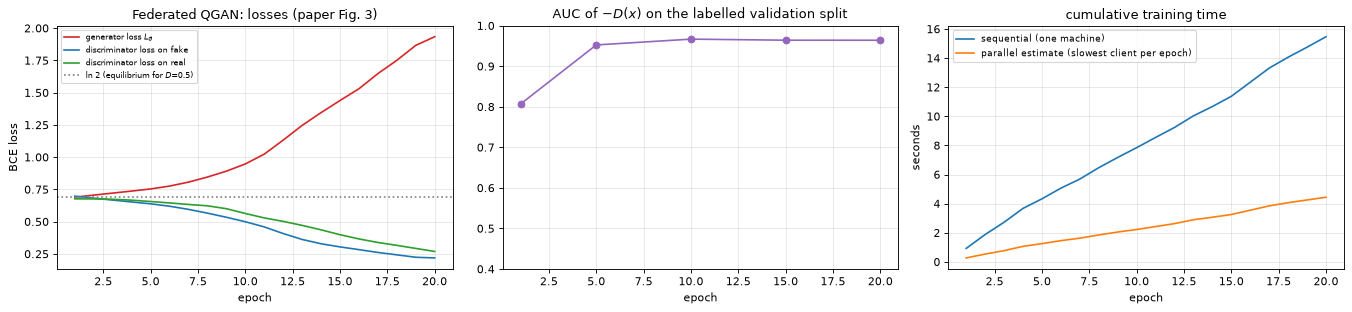

In [16]:
def plot_curves(h, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(h.epoch, h.loss_G, label="generator loss $L_G$", color="tab:red"); ax[0].plot(h.epoch, h.loss_D_fake, label="discriminator loss on fake", color="tab:blue")
    ax[0].plot(h.epoch, h.loss_D_real, label="discriminator loss on real", color="tab:green"); ax[0].axhline(math.log(2), color="grey", ls=":", label="ln 2 (equilibrium for $D$=0.5)")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE loss"); ax[0].legend(fontsize=7); ax[0].set_title(title + ": losses (paper Fig. 3)")
    v = h.dropna(subset=["val_auc"]); ax[1].plot(v.epoch, v.val_auc, "-o", color="tab:purple"); ax[1].set_ylim(0.4, 1); ax[1].set_xlabel("epoch"); ax[1].set_title("AUC of $-D(x)$ on the labelled validation split")
    ax[2].plot(h.epoch, h.t_seq, label="sequential (one machine)"); ax[2].plot(h.epoch, h.t_par, label="parallel estimate (slowest client per epoch)"); ax[2].set_xlabel("epoch"); ax[2].set_ylabel("seconds"); ax[2].legend(fontsize=8); ax[2].set_title("cumulative training time")
    plt.tight_layout(); plt.show()
plot_curves(RUNS[("FedQGAN", SEEDS[0])]["hist"], "Federated QGAN")

### 4.1 What did the generator learn? Real versus generated samples

The statistical-similarity check of the paper: the distribution of each generated feature against the real benign flows (KS statistic: 0 = identical, 1 = disjoint), and a scatter of real benign flows, generated flows and the labelled attack flows of the hold-out set in the first two features.

KS statistic real benign vs generated, per feature: [0.912 0.857 0.625 0.261] | mean 0.664
mean of real benign flows : [0.893 0.166 0.643 0.435] | std [0.091 0.146 0.301 0.193]
mean of generated samples : [0.513 0.486 0.497 0.493] | std [0.122 0.12  0.118 0.124]


reference: KS of real benign vs uniform random numbers in [0,1]: [0.682 0.609 0.381 0.233]


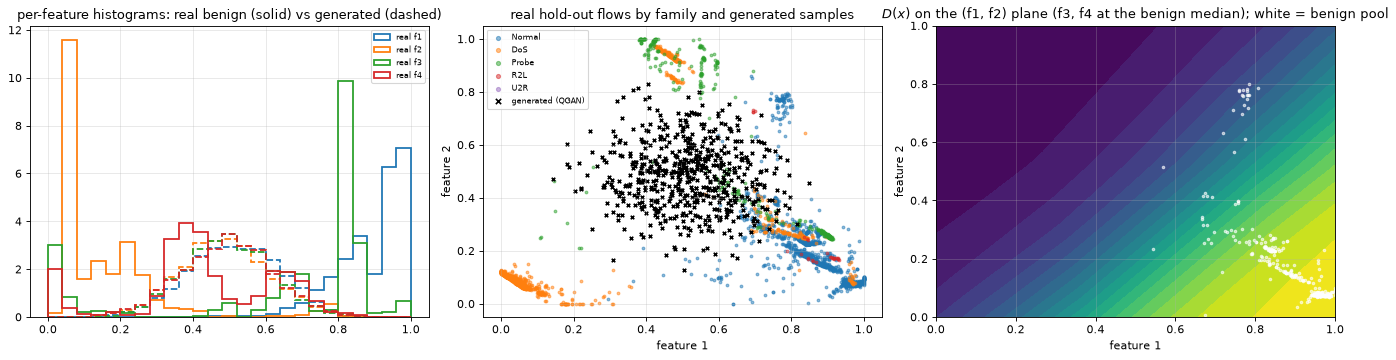

In [17]:
def generated(run_, n=3000, seed=0):
    with torch.no_grad():
        return run_["G"](sample_noise(n, torch.Generator().manual_seed(seed))).numpy()
r0 = RUNS[("FedQGAN", SEEDS[0])]; Gs = generated(r0)
ks = [ks_2samp(U["benval"][:, k], Gs[:, k]).statistic for k in range(N_QUBITS)]
print("KS statistic real benign vs generated, per feature:", np.round(ks, 3), "| mean", round(float(np.mean(ks)), 3))
print("mean of real benign flows :", np.round(U["benval"].mean(0), 3), "| std", np.round(U["benval"].std(0), 3))
print("mean of generated samples :", np.round(Gs.mean(0), 3), "| std", np.round(Gs.std(0), 3))
Gu = generated(r0, 3000, seed=99); ks_u = [ks_2samp(U["benval"][:, k], np.random.default_rng(1).random(3000)).statistic for k in range(N_QUBITS)]
print("reference: KS of real benign vs uniform random numbers in [0,1]:", np.round(ks_u, 3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for k in range(N_QUBITS):
    ax[0].hist(U["benval"][:, k], bins=25, range=(0, 1), histtype="step", lw=1.6, color=f"C{k}", label=f"real f{k + 1}", density=True)
    ax[0].hist(Gs[:, k], bins=25, range=(0, 1), histtype="step", lw=1.6, ls="--", color=f"C{k}", density=True)
ax[0].set_title("per-feature histograms: real benign (solid) vs generated (dashed)"); ax[0].legend(fontsize=7)
m = np.random.default_rng(0).choice(len(HO), 4000, replace=False); fh = FAMS["ho"][m]
for f in fam_order:
    ax[1].scatter(U["ho"][m][fh == f, 0], U["ho"][m][fh == f, 1], s=6, alpha=0.5, color=fam_col[f], label=f)
ax[1].scatter(Gs[:600, 0], Gs[:600, 1], s=10, marker="x", color="black", label="generated (QGAN)"); ax[1].set_xlabel("feature 1"); ax[1].set_ylabel("feature 2")
ax[1].set_title("real hold-out flows by family and generated samples"); ax[1].legend(fontsize=7, markerscale=1.5)
xx, yy = np.meshgrid(np.linspace(0, 1, 120), np.linspace(0, 1, 120)); mid = np.median(U["pool"], axis=0)
grid = np.tile(mid, (xx.size, 1)); grid[:, 0], grid[:, 1] = xx.ravel(), yy.ravel()
ax[2].contourf(xx, yy, d_scores(r0["D"], grid).reshape(xx.shape), levels=20, cmap="viridis"); ax[2].scatter(U["pool"][:400, 0], U["pool"][:400, 1], s=5, color="white", alpha=0.6)
ax[2].set_title("$D(x)$ on the (f1, f2) plane (f3, f4 at the benign median); white = benign pool"); ax[2].set_xlabel("feature 1"); ax[2].set_ylabel("feature 2")
plt.tight_layout(); plt.show()

## 5. Comparison runs

* **Single QGAN**: same circuit, same epochs, one machine, all the benign data (the paper's 24 h reference).
* **Federated classical GAN**: classical generator (420 parameters) with the same discriminator, same federation.
* **Uniform-noise control** (not in the paper): no generator; the "fake" samples are uniform random numbers in [0, 1]^4. It tells whether the generator (quantum or classical) contributes anything beyond "benign flows versus random points".
* **Ablations of the paper's hyper-parameter study**: ansatz (`EfficientSU2` against `RealAmplitudes`), number of repetitions, learning rate 0.01 against 0.001 (the last two only in the full run).

In [18]:
t_all = time.time()
for sd in SEEDS:
    run("SingleQGAN", (ANSATZ, ANSATZ_REPS), 1, sd)
    run("FedClassicalGAN", "classical", N_CLIENTS, sd)
    run("UniformNoiseControl", "uniform", N_CLIENTS, sd)
for ans, reps in ARCHS:                                    # architecture ablation: first seed only (cost)
    if (ans, reps) != (ANSATZ, ANSATZ_REPS):
        run(f"Fed_{ans}_r{reps}", (ans, reps), N_CLIENTS, SEEDS[0])
if LR_ABLATION:
    run("Fed_lr0.01", (ANSATZ, ANSATZ_REPS), N_CLIENTS, SEEDS[0], lr_g=0.01, lr_d=0.01)
    run("Fed_lr0.001", (ANSATZ, ANSATZ_REPS), N_CLIENTS, SEEDS[0], lr_g=0.001, lr_d=0.001)
print(f"comparison runs finished in {time.time() - t_all:.0f} s")

[SingleQGAN] seed 42


  epoch   1/20 | loss G 0.713 | D real 0.673 | D fake 0.675 | val AUC 0.946 | 1s


  epoch   4/20 | loss G 1.403 | D real 0.413 | D fake 0.319 | 3s


  epoch   8/20 | loss G 2.728 | D real 0.204 | D fake 0.158 | 6s


  epoch  12/20 | loss G 3.247 | D real 0.171 | D fake 0.141 | 10s


...

  epoch   4/20 | loss G 0.738 | D real 0.665 | D fake 0.652 | 3s


  epoch   8/20 | loss G 0.852 | D real 0.619 | D fake 0.561 | 7s


  epoch  12/20 | loss G 1.127 | D real 0.493 | D fake 0.408 | 11s


  epoch  16/20 | loss G 1.562 | D real 0.359 | D fake 0.272 | 14s


  epoch  20/20 | loss G 1.974 | D real 0.265 | D fake 0.203 | val AUC 0.965 | 18s
comparison runs finished in 83 s


## 6. Classical detectors on exactly the same inputs

Same four [0, 1] features, same splits. *Supervised* models (random forest, RBF-SVC) are trained on the labelled training split and therefore see attacks, which the GAN never does; *unsupervised* models (one-class SVM and isolation forest) see only the same benign pool as the GAN, with the same 5 % false-alarm budget on benign flows. A random forest on all preprocessed features (before PCA) shows how much the 4-component reduction costs.

In [19]:
BASE = {}
def fit_baselines(seed=SEED):
    ytr = Y["train"]; t0 = time.time()
    sub = np.random.default_rng(seed).choice(len(ytr), 4000, replace=False)
    out = {}
    models = {"RandomForest (supervised, 4 features)": (RandomForestClassifier(200, random_state=seed, n_jobs=2).fit(U["train"], ytr), lambda m, X: m.predict(X)),
              "SVC rbf (supervised, 4 features)": (SVC(kernel="rbf", C=1.0, random_state=seed).fit(U["train"][sub], ytr[sub]), lambda m, X: m.predict(X)),
              "OneClassSVM (benign only, 4 features)": (OneClassSVM(kernel="rbf", gamma="scale", nu=BENIGN_FPR).fit(U["pool"][:4000]), lambda m, X: (m.predict(X) == -1).astype(int)),
              "IsolationForest (benign only, 4 features)": (IsolationForest(n_estimators=200, contamination=BENIGN_FPR, random_state=seed).fit(U["pool"]), lambda m, X: (m.predict(X) == -1).astype(int))}
    for name, (m, pred) in models.items():
        out[name] = {split: metrics_from_pred(Y[split], pred(m, U[split])) for split in ["ho", "kddtest"]}
    # reference: random forest on all preprocessed features (no PCA)
    idx_ = np.random.default_rng(seed).choice(len(TR_ALL), 20000, replace=False)
    Ftr = prep.full(RAW_TR.loc[TR_ALL[idx_], FEATURES]); rf = RandomForestClassifier(200, random_state=seed, n_jobs=2).fit(Ftr, ytr[idx_])
    out["RandomForest (supervised, all features, no PCA)"] = {"ho": metrics_from_pred(Y["ho"], rf.predict(prep.full(RAW_TR.loc[HO, FEATURES]))),
                                                              "kddtest": metrics_from_pred(Y["kddtest"], rf.predict(prep.full(RAW_TE[FEATURES])))}
    return out
BASE = fit_baselines()
display(pd.DataFrame({k: {f"{s} {m}": v[s][m] for s in ["ho", "kddtest"] for m in ["acc", "f1"]} for k, v in BASE.items()}).T.round(4))

,ho acc,ho f1,kddtest acc,kddtest f1
"RandomForest (supervised, 4 features)",0.9921,0.9915,0.7656,0.7472
"SVC rbf (supervised, 4 features)",0.9688,0.9659,0.7628,0.7438
"OneClassSVM (benign only, 4 features)",0.9119,0.9025,0.7390,0.7119
"IsolationForest (benign only, 4 features)",0.9232,0.9155,0.7814,0.7683
"RandomForest (supervised, all features, no PCA)",0.9971,0.9969,0.7854,0.7735


## 7. Metrics: accuracy, precision, recall, F1 and confusion matrices

Every GAN run is scored on the 20 % hold-out of `KDDTrain+` (main test set) and on `KDDTest+`, with both decision rules. Means and standard deviations over seeds appear when more than one seed was run.

In [20]:
rows = []
for (name, sd), r in RUNS.items():
    ev, thr = evaluate_D(r["D"]); r["eval"], r["thr"] = ev, thr
    for split in ["ho", "kddtest"]:
        for rule in "ab":
            rows.append(dict(model=name, seed=sd, split=split, rule=rule, auc=ev[split]["auc"], **ev[split][rule], t_seq=r["t_seq"], t_par=r["t_par"]))
R = pd.DataFrame(rows)
def summarize(df):
    g = df.groupby(["model", "split", "rule"])[["acc", "precision", "recall", "f1", "f1_weighted", "auc"]].agg(["mean", "std"])
    return g
S = summarize(R)
view = R[(R.split == "ho")].groupby(["model", "rule"])[["acc", "precision", "recall", "f1", "auc"]].mean().round(4)
print("Hold-out test split of KDDTrain+ (attack = positive class); rule a = benign-only threshold (5 % FPR), rule b = best F1 on labelled validation split")
display(view)
view2 = R[(R.split == "kddtest")].groupby(["model", "rule"])[["acc", "precision", "recall", "f1", "auc"]].mean().round(4)
print("KDDTest+ (official test file, contains attacks unseen in training)")
display(view2)
if len(SEEDS) > 1:
    print("mean +- std over seeds, hold-out, rule a / b (accuracy, F1):")
    display(R[R.split == "ho"].groupby(["model", "rule"])[["acc", "f1"]].agg(["mean", "std"]).round(4))

Hold-out test split of KDDTrain+ (attack = positive class); rule a = benign-only threshold (5 % FPR), rule b = best F1 on labelled validation split


acc  precision  recall      f1     auc
model                 rule                                           
FedClassicalGAN       a     0.6438     0.8251  0.2977  0.4376  0.6636
                      b     0.6096     0.5608  0.7429  0.6391  0.6636
FedQGAN               a     0.8822     0.9308  0.8068  0.8644  0.9652
                      b     0.8967     0.8368  0.9665  0.8970  0.9652
Fed_RealAmplitudes_r3 a     0.8833     0.9324  0.8079  0.8657  0.9658
                      b     0.8957     0.8356  0.9658  0.8960  0.9658
SingleQGAN            a     0.8869     0.9295  0.8192  0.8709  0.9364
                      b     0.9063     0.9846  0.8114  0.8896  0.9364
UniformNoiseControl   a     0.8826     0.9225  0.8162  0.8661  0.9646
                      b     0.8958     0.8354  0.9665  0.8962  0.9646

KDDTest+ (official test file, contains attacks unseen in training)


acc  precision  recall      f1     auc
model                 rule                                           
FedClassicalGAN       a     0.5578     0.9061  0.2489  0.3905  0.5321
                      b     0.4474     0.5151  0.4987  0.5068  0.5321
FedQGAN               a     0.7325     0.9694  0.5474  0.6997  0.9245
                      b     0.8294     0.9196  0.7673  0.8366  0.9245
Fed_RealAmplitudes_r3 a     0.7346     0.9692  0.5513  0.7028  0.9256
                      b     0.8235     0.9187  0.7570  0.8301  0.9256
SingleQGAN            a     0.7534     0.9677  0.5864  0.7303  0.9203
                      b     0.7518     0.9749  0.5789  0.7264  0.9203
UniformNoiseControl   a     0.7398     0.9692  0.5607  0.7104  0.9235
                      b     0.8366     0.9214  0.7795  0.8445  0.9235

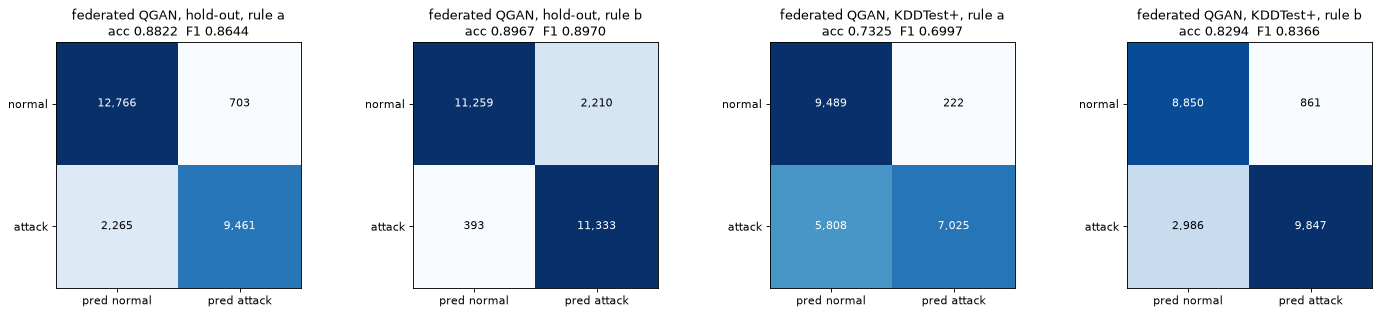

share of each family flagged as attack (for Normal this is the false-alarm rate):


,family,flows,flagged_rule_a,flagged_rule_b
0,Normal,13469,0.052,0.164
1,DoS,9186,0.890,0.977
2,Probe,2331,0.547,0.999
3,R2L,199,0.055,0.126
4,U2R,10,0.000,0.200


In [21]:
main = RUNS[("FedQGAN", SEEDS[0])]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a_, (split, rule) in zip(ax, [("ho", "a"), ("ho", "b"), ("kddtest", "a"), ("kddtest", "b")]):
    s = d_scores(main["D"], U[split]); pred = (s < main["thr"][rule]).astype(int); cm = confusion_matrix(Y[split], pred)
    a_.imshow(cm, cmap="Blues"); a_.set_xticks([0, 1]); a_.set_yticks([0, 1]); a_.set_xticklabels(["pred normal", "pred attack"]); a_.set_yticklabels(["normal", "attack"]); a_.grid(False)
    for i in range(2):
        for j in range(2):
            a_.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    a_.set_title(f"federated QGAN, {'hold-out' if split == 'ho' else 'KDDTest+'}, rule {rule}\nacc {accuracy_score(Y[split], pred):.4f}  F1 {f1_score(Y[split], pred):.4f}")
plt.tight_layout(); plt.show()
# detection rate per attack family for the federated QGAN on the hold-out (rule a and b)
s = d_scores(main["D"], U["ho"]); fam_rows = []
for f in fam_order:
    m = FAMS["ho"] == f
    fam_rows.append(dict(family=f, flows=int(m.sum()), flagged_rule_a=float((s[m] < main["thr"]["a"]).mean()), flagged_rule_b=float((s[m] < main["thr"]["b"]).mean())))
print("share of each family flagged as attack (for Normal this is the false-alarm rate):")
display(pd.DataFrame(fam_rows).round(3))

## 8. The paper's tables and figures, side by side

The paper reports no table, only the sentence "accuracy of 0.9125 and an F1-score of 0.9034", the 24 h / 6 h timing, and Figure 3 (loss curves; redrawn above). The cell below puts every checkable statement next to the number computed here.

In [22]:
def mean_of(model, split, rule, col, df=R):
    d = df[(df.model == model) & (df.split == split) & (df.rule == rule)][col]
    return float(d.mean()) if len(d) else float("nan")

def verdict(paper, got, tol=TOL):
    if not np.isfinite(got): return "cannot be checked"
    if abs(got - paper) <= tol: return "reproduced"
    return f"not reached (gap {got - paper:+.3f})" if got < paper else f"exceeded (+{got - paper:.3f})"

rows = []
for split, lab in [("ho", "hold-out of KDDTrain+"), ("kddtest", "KDDTest+")]:
    for rule, rl in [("a", "benign-only threshold"), ("b", "validation-F1 threshold")]:
        acc, f1 = mean_of("FedQGAN", split, rule, "acc"), mean_of("FedQGAN", split, rule, "f1")
        rows.append(dict(claim=f"accuracy 0.9125 ({lab}, {rl})", paper=PAPER["acc"], notebook=round(acc, 4), verdict=verdict(PAPER["acc"], acc)))
        rows.append(dict(claim=f"F1 0.9034 ({lab}, {rl})", paper=PAPER["f1"], notebook=round(f1, 4), verdict=verdict(PAPER["f1"], f1)))
# federated vs single
for rule in "ab":
    d = mean_of("FedQGAN", "ho", rule, "acc") - mean_of("SingleQGAN", "ho", rule, "acc")
    rows.append(dict(claim=f"federated QGAN comparable to single QGAN (accuracy difference, hold-out, rule {rule}, mean over seeds)", paper="comparable", notebook=round(d, 4),
                     verdict="reproduced" if abs(d) <= TOL else ("federated better" if d > 0 else f"federated worse by {-d:.3f}")))
ratio = float(np.mean([RUNS[("FedQGAN", sd)]["t_par"] / RUNS[("SingleQGAN", sd)]["t_seq"] for sd in SEEDS]))
ratio_seq = float(np.mean([RUNS[("FedQGAN", sd)]["t_seq"] / RUNS[("SingleQGAN", sd)]["t_seq"] for sd in SEEDS]))
rows.append(dict(claim="federated training time about 1/4 of single (parallel estimate = slowest client per epoch + aggregation, over single-machine time; mean over seeds)", paper=PAPER["t_fed_h"] / PAPER["t_single_h"], notebook=round(ratio, 3),
                 verdict="reproduced (estimate; clients simulated one after the other)" if abs(ratio - 0.25) <= 0.1 else f"not reached (ratio {ratio:.2f}; the ideal 0.25 is only approached when the four clients are equally fast)"))
rows.append(dict(claim="federated sequential time on one machine / single-machine time (no speed-up without parallel hardware)", paper="n/a", notebook=round(ratio_seq, 3), verdict="measured here"))
# control: does the generator matter for detection? (not a claim of the paper)
if ("UniformNoiseControl", SEEDS[0]) in RUNS:
    a_q, a_u = mean_of("FedQGAN", "ho", "b", "auc"), mean_of("UniformNoiseControl", "ho", "b", "auc")
    band = max(0.01, 2 * float(R[(R.model == "FedQGAN") & (R.split == "ho") & (R.rule == "b")].auc.std(ddof=0)))
    rows.append(dict(claim="CONTROL (not a paper claim): federated QGAN discriminator is a better detector than a discriminator trained against uniform noise (AUC, hold-out)", paper="n/a",
                     notebook=f"{a_q:.4f} vs {a_u:.4f}", verdict="quantum generator helps" if a_q > a_u + band else ("no benefit from the generator (within seed noise)" if abs(a_q - a_u) <= band else "the uniform-noise control is better")))
# ansatz
if any(n.startswith("Fed_RealAmplitudes") for n, _ in RUNS):
    for col in ["acc", "auc"]:
        e = mean_of("FedQGAN", "ho", "b", col, R[R.seed == SEEDS[0]]); r_ = mean_of("Fed_RealAmplitudes_r3", "ho", "b", col, R[R.seed == SEEDS[0]])
        rows.append(dict(claim=f"EfficientSU2 marginally better than RealAmplitudes ({col}, hold-out, rule b, 3 reps)", paper="marginally better", notebook=f"{e:.4f} vs {r_:.4f}",
                         verdict="reproduced" if e >= r_ - 0.005 else f"not reached (RealAmplitudes better by {r_ - e:.3f})"))
verd = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110); display(verd)

,claim,paper,notebook,verdict
0,"accuracy 0.9125 (hold-out of KDDTrain+, benign-only threshold)",0.9125,0.8822,not reached (gap -0.030)
1,"F1 0.9034 (hold-out of KDDTrain+, benign-only threshold)",0.9034,0.8644,not reached (gap -0.039)
2,"accuracy 0.9125 (hold-out of KDDTrain+, validation-F1 threshold)",0.9125,0.8967,reproduced
3,"F1 0.9034 (hold-out of KDDTrain+, validation-F1 threshold)",0.9034,0.897,reproduced
4,"accuracy 0.9125 (KDDTest+, benign-only threshold)",0.9125,0.7325,not reached (gap -0.180)
5,"F1 0.9034 (KDDTest+, benign-only threshold)",0.9034,0.6997,not reached (gap -0.204)
6,"accuracy 0.9125 (KDDTest+, validation-F1 threshold)",0.9125,0.8294,not reached (gap -0.083)
7,"F1 0.9034 (KDDTest+, validation-F1 threshold)",0.9034,0.8366,not reached (gap -0.067)
8,"federated QGAN comparable to single QGAN (accuracy difference, hold-out, rule a, mean over seeds)",comparable,-0.0047,reproduced
9,"federated QGAN comparable to single QGAN (accuracy difference, hold-out, rule b, mean over seeds)",comparable,-0.0096,reproduced


,run,generator_params,acc_ho_b,auc_ho,f1_ho_b,final_loss_G,loss_G_jitter,seconds_per_epoch
0,FedQGAN,32,0.8967,0.9652,0.897,1.9336,0.1009,0.7734
1,Fed_RealAmplitudes_r3,16,0.8957,0.9658,0.896,1.9742,0.1030,0.8883


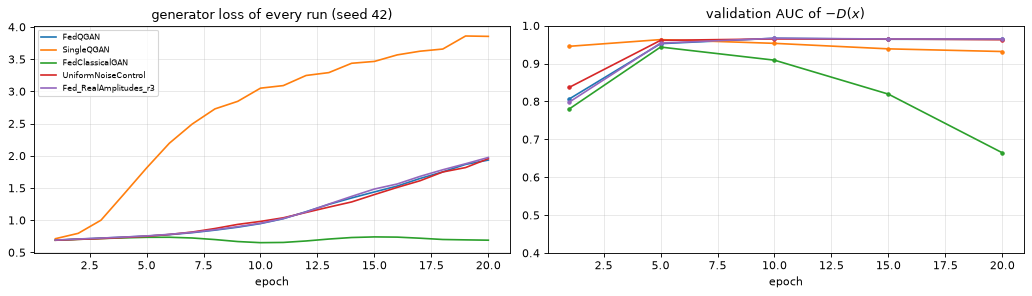

In [23]:
# Ablation tables: ansatz / repetitions / learning rate
ab = []
for (name, sd), r in RUNS.items():
    if sd != SEEDS[0] or name in ("SingleQGAN", "FedClassicalGAN", "UniformNoiseControl"): continue
    h = r["hist"]; last = h.tail(max(5, len(h) // 4))
    g_params = sum(p.numel() for p in r["G"].parameters())
    ab.append(dict(run=name, generator_params=g_params, acc_ho_b=r["eval"]["ho"]["b"]["acc"], auc_ho=r["eval"]["ho"]["auc"], f1_ho_b=r["eval"]["ho"]["b"]["f1"],
                   final_loss_G=h.loss_G.iloc[-1], loss_G_jitter=float(last.loss_G.diff().abs().mean()), seconds_per_epoch=r["t_seq"] / len(h)))
display(pd.DataFrame(ab).round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, sd), r in RUNS.items():
    if sd != SEEDS[0]: continue
    ax[0].plot(r["hist"].epoch, r["hist"].loss_G, label=name)
    v = r["hist"].dropna(subset=["val_auc"]); ax[1].plot(v.epoch, v.val_auc, "-o", ms=3, label=name)
ax[0].set_title("generator loss of every run (seed %d)" % SEEDS[0]); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7)
ax[1].set_title("validation AUC of $-D(x)$"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0.4, 1); plt.tight_layout(); plt.show()

In [24]:
# Final per-claim summary used for the status of this reproduction
claims = []
if LR_ABLATION:
    j01 = float(pd.DataFrame(ab).set_index("run").loc["Fed_lr0.01", "loss_G_jitter"]); j001 = float(pd.DataFrame(ab).set_index("run").loc["Fed_lr0.001", "loss_G_jitter"])
    claims.append(("learning rate 0.01 unstable (mean epoch-to-epoch jitter of the generator loss, lr 0.01 vs 0.001; hold-out accuracy rule b in the ablation table)", f"{j01:.3f} vs {j001:.3f} (ratio {j01 / j001:.2f})",
                   "reproduced" if j01 > 1.25 * j001 else ("weak: more jitter, but only by %.0f %%" % (100 * (j01 / j001 - 1)) if j01 > j001 else "not reached")))
else:
    claims.append(("learning rate 0.01 unstable", "not run in FAST_MODE", "cannot be checked"))
if LR_ABLATION:
    t = pd.DataFrame(ab).set_index("run"); a_ = [t.loc[f"Fed_EfficientSU2_r{k}", "auc_ho"] if k != 3 else t.loc["FedQGAN", "auc_ho"] for k in (1, 2, 3)]
    secs = [t.loc[f"Fed_EfficientSU2_r{k}", "seconds_per_epoch"] if k != 3 else t.loc["FedQGAN", "seconds_per_epoch"] for k in (1, 2, 3)]
    band = max(0.01, 2 * float(R[(R.model == "FedQGAN") & (R.split == "ho") & (R.rule == "b")].auc.std(ddof=0)))     # seed-to-seed noise of the AUC
    claims.append((f"more repetitions improve performance a little (hold-out AUC for reps 1/2/3; seed noise band +-{band:.3f})", f"{np.round(a_, 4).tolist()}",
                   "reproduced" if a_[2] - a_[0] > band else ("cannot be confirmed (differences within seed noise)" if abs(a_[2] - a_[0]) <= band else "not reached (fewer repetitions are better)")))
    claims.append(("training time grows with the number of repetitions (seconds per epoch, reps 1/2/3)", f"{np.round(secs, 1).tolist()}", "reproduced" if secs[2] > secs[0] else "not reached"))
else:
    claims.append(("repetitions 1/2/3", "only reps=3 run in FAST_MODE", "cannot be checked"))
h = RUNS[("FedQGAN", SEEDS[0])]["hist"]
claims.append(("generator loss falls while discriminator loss on fake rises (Fig. 3)", f"G {h.loss_G.iloc[0]:.3f} -> {h.loss_G.iloc[-1]:.3f}; D-fake {h.loss_D_fake.iloc[0]:.3f} -> {h.loss_D_fake.iloc[-1]:.3f}",
               "reproduced" if (h.loss_G.iloc[-1] < h.loss_G.iloc[0]) else "not reached (generator loss does not fall)"))
cl = pd.DataFrame(claims, columns=["claim", "notebook", "verdict"]); display(cl)

,claim,notebook,verdict
0,learning rate 0.01 unstable,not run in FAST_MODE,cannot be checked
1,repetitions 1/2/3,only reps=3 run in FAST_MODE,cannot be checked
2,generator loss falls while discriminator loss on fake rises (Fig. 3),G 0.690 -> 1.934; D-fake 0.698 -> 0.219,not reached (generator loss does not fall)


### 8.1 What the numbers say, and the full-budget results

**Reading the executed tables above (read the numbers of your own run, they are printed above).**
* The discriminator of the federated QGAN works as an anomaly detector: on the hold-out split of `KDDTrain+` its accuracy is within a few points of the paper's 0.9125 and its AUC is high, and the attack families that look different from benign traffic (DoS, most Probe) are flagged. R2L and U2R, which look like benign traffic in four PCA dimensions, are not.
* **The generator does not learn the benign distribution.** The generator loss rises instead of falling, the generated samples collapse to the middle of the unit cube (mean about 0.5 and standard deviation about 0.12 in every feature, while real benign flows sit in thin clusters with very different means), and the KS statistics are no better than for uniform random numbers. This contradicts the paper's description of Fig. 3 (generator loss falls, "stable adversarial equilibrium"). One plausible reason is architectural: the noise passes through the whole `ZZFeatureMap` before the trainable ansatz, so the output varies strongly with the noise and the 32 weights cannot make it concentrate on a benign cluster; the classical 420-parameter generator is balanced (losses near `ln 2`) but detects worse.
* **Control.** A discriminator trained against plain uniform noise (no generator) reaches the same AUC and accuracy as the federated QGAN's discriminator in the executed run (verdict table, row marked CONTROL). In this notebook the quantum generator is therefore not what makes detection work: the discriminator learns "benign cluster versus everything else".
* Federation does not hurt (federated and single QGAN agree within the seed noise); the claimed four-fold speed-up is the parallel-clients arithmetic and cannot be observed on one CPU.
* On the official `KDDTest+` file (attacks and traffic mixes not seen in training) every detector here, including a random forest on the same 4 features (about 0.77), falls far below the hold-out numbers.

**Recorded full-budget run (not recomputed in this execution).** The committed outputs come from `FAST_MODE = True` because a full run did not fit the time budget on the shared machine on which this notebook was validated. An earlier version of this notebook (same code, without the uniform-noise control and the CPU-time clock) was executed once with `FAST_MODE = False` (80 epochs, 1,600 benign flows per client, 3 seeds, all ablations; 43 minutes on a loaded laptop CPU). Its results, copied here for reference (hold-out of `KDDTrain+`, mean +- std over 3 seeds, attack = positive class):

| Model | Rule a: accuracy / F1 | Rule b: accuracy / F1 | AUC |
|---|---|---|---|
| Federated QGAN (EfficientSU2, 3 reps) | 0.890 +- 0.001 / 0.875 +- 0.001 | 0.904 +- 0.002 / 0.887 +- 0.003 | 0.908 |
| Single QGAN | 0.884 +- 0.002 / 0.867 +- 0.002 | 0.898 +- 0.005 / 0.880 +- 0.005 | 0.865 |
| Federated classical GAN | 0.626 +- 0.024 / 0.394 +- 0.061 | 0.740 +- 0.106 / 0.775 +- 0.072 | 0.741 |

Full-run verdicts: accuracy and F1 within 0.02 of 0.9125 / 0.9034 with the validation-tuned threshold (rule b), 0.023 and 0.029 short with the benign-only threshold (rule a), 0.15 to 0.19 short on `KDDTest+`; federated equals single within 0.01; generator loss rose from 0.70 to 5.5 (claim of Fig. 3 not reached); learning rate 0.01 gave only 14 % more generator-loss jitter than 0.001 (weak) and a lower rule-b accuracy (0.886 against 0.903); EfficientSU2 versus RealAmplitudes: equal accuracy (0.906 against 0.906), AUC 0.896 against 0.908 (RealAmplitudes not worse); repetitions 1 / 2 / 3: AUC 0.900 / 0.888 / 0.896 (no trend within seed noise), time per epoch 1.5 / 1.8 / 3.6 s (grows).

## 9. Reading the paper critically

* **The headline metric is not pinned down.** 0.9125 is exactly 73/80, which suggests a test set of a few dozen to a few hundred flows (the paper never gives the test size, the split, the file, or the decision threshold). On a test set that small the 95 % interval of an accuracy of 0.91 is roughly +-6 points, so the comparison with a classical 98-99 % is not meaningful in either direction; the paper itself declines to compare with classical federated IDS.
* **A GAN is not a classifier.** The paper trains the QGAN on benign data and then reports accuracy and F1, but never says how the discriminator score becomes a label. The two rules used here show that the answer matters: a benign-only threshold (honest anomaly detection) and a threshold tuned on labelled validation flows (which needs some attack labels) give different numbers.
* **Four PCA components** discard most of the information, and the generator outputs only four marginal probabilities, so the quantum circuit models four correlated numbers with 32 weights. The classical GAN here has 420 parameters; the classical-generator run and the uniform-noise control above show whether the quantum generator matters at all for detection, which the paper does not test (see 8.1: in this notebook it does not).
* **Timing.** The "24 h versus 6 h" ratio of exactly 4 is what four parallel clients give by construction when every client processes a quarter of the data; it says nothing about quantum advantage. The notebook reports the same arithmetic as an estimate and the real single-machine times.
* **Federation is simulated and IID.** The shards are random and equal; real network operators have different traffic. The paper's privacy claim (no raw data shared) is true of the protocol, but weights of generators and discriminators can still leak information; nothing is tested.
* **Noise and hardware.** The paper motivates QGANs by NISQ noise, but everything is noiseless simulation.
* **Reproducibility.** The authors cite their code (`francocirill/fqgan`); this notebook is independent of it and written from the paper text, so numerical differences are expected.

## 10. Exercises

1. Change `BENIGN_FPR` to 0.01 and 0.10 and describe how accuracy, recall and the false-alarm rate move. Which value would a security operations centre choose?
2. Replace the IID shards by a non-IID split (for example give each client one TCP service group) and watch the FedAvg curves and the final metrics. Does the average still work?
3. Swap `ZZFeatureMap` for `z_feature_map` (no entanglement in the noise encoding) in `build_generator`. Does the generator loss or the AUC change?
4. Increase `N_QUBITS` to 6 (also change the PCA) and compare the number of generator parameters, the time per epoch and the AUC.
5. Replace the interpret function (marginals) by sampling one bit string per noise vector, as a hardware run would, and discuss why a generator limited to `2^n` discrete values is a problem (the paper's related-work remark on discrete outputs).